# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

In [3]:
# 문제 설정
n = 200  # 총 시행 횟수
x = 12   # 관찰된 성공 횟수
p = 0.1  # 귀무가설에서의 성공 확률

print(f"관찰 결과: {n}번 시도 중 {x}번 성공 (관찰 성공률 {x/n:.1%})")

관찰 결과: 200번 시도 중 12번 성공 (관찰 성공률 6.0%)


**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

In [4]:
# [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설):성공 확률은 10% 이다
# H₁ (대립가설):성공 확률이 10% 보다 낮다

In [5]:
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?

# 여기에 코드를 작성해주세요.
result = stats.binomtest(x, n, p, alternative='less')
p_value = result.pvalue
print(f"p-값: {p_value:.4f}")

p-값: 0.0320


In [6]:
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05
if p_value < alpha:
    print(f"p-값({p_value:.4f}) < {alpha} → 귀무가설 기각: 성공 확률은 10%보다 낮다고 볼 수 있습니다.")
else:
    print(f"p-값({p_value:.4f}) ≥ {alpha} → 귀무가설 기각 실패: 성공 확률이 10%보다 낮다는 근거가 부족합니다.")


p-값(0.0320) < 0.05 → 귀무가설 기각: 성공 확률은 10%보다 낮다고 볼 수 있습니다.


In [7]:
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# 힌트: numpy의 이항분포 랜덤 함수(np.random.binomial)를 사용해보세요.

# 여기에 코드를 작성해주세요.
np.random.seed(42)
n_sim = 10_000
simulated = np.random.binomial(n=n, p=p, size=n_sim)

sim_p_value = np.mean(simulated <= x)  # 관찰값 이하가 나온 비율
print(f"시뮬레이션 평균 성공 횟수: {simulated.mean():.2f}")
print(f"시뮬레이션 기반 p-값: {sim_p_value:.4f}")

시뮬레이션 평균 성공 횟수: 19.91
시뮬레이션 기반 p-값: 0.0313


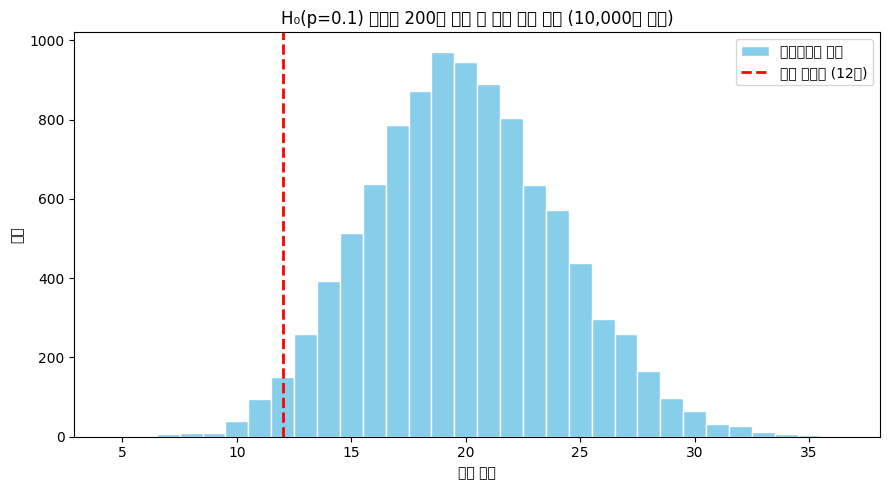

In [8]:
# [문제 1] Q5. 시뮬레이션 결과를 히스토그램으로 그려봅시다.
# 실제 관찰값(12번 성공)을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.rcParams['font.family'] = 'Malgun Gothic'   # macOS는 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

bins = np.arange(simulated.min(), simulated.max() + 2) - 0.5
plt.figure(figsize=(9, 5))
plt.hist(simulated, bins=bins, color='skyblue', edgecolor='white', label='시뮬레이션 결과')
plt.axvline(x, color='red', linestyle='--', linewidth=2, label=f'실제 관찰값 ({x}번)')
plt.title(f'H₀(p={p}) 하에서 {n}번 시행 시 성공 횟수 분포 ({n_sim:,}회 반복)')
plt.xlabel('성공 횟수')
plt.ylabel('빈도')
plt.legend()
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?

In [9]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1.Q5에서 그린 히스토그램에 나온 빨가선으 기준으로 왼쪽부분 전부가 p-value에 해당한다.
전체 10,000번 중 그 영역에 해당하는 비율이 약 3.2%이다.

2. 드문 일이다. 확률이 10%라면 200번 중 평균이 20번 정도 성공해야하고, 그래프도 20 근처에 몰려있다. 12회는 분포의 왼쪽 코리 끝에 있어서, 100번 실험하면 3번정도 나올까 말까 한 결과이다.

3. 게임회사가 뽑기 확률이 10%인데,  200번 뽑으면 보통 20번 한번은 당첨이 되어야하는ㅔ,내가 12번 정도를 뽑았는데 당첨확은 3%밖에 안된다.

4. P-value가 약 0.0000044으로 훨씬 작아진다. 200번일때의 0.032와 비교하면 수천배 작은 값이다. 시행횟수가 늘어나면 분포가 평균 주변으로 더 좁게 몰린다.

# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

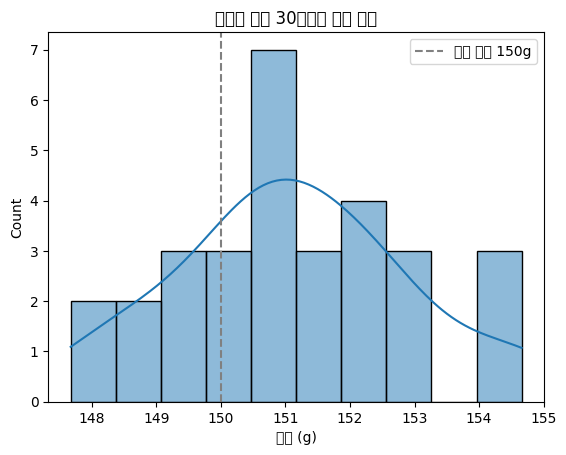

In [10]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [11]:
# [문제 2] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 과자 한 봉지 평균 무게는 150g이다
# H₁ (대립가설): 과자 한 봉지 평균 무게는 150g이 아니다

In [12]:
# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.

# 여기에 코드를 작성해주세요.
t_stat, p_value = stats.ttest_1samp(sample_weights, popmean=pop_mean)
print(f"표본 평균: {sample_weights.mean():.2f}g")
print(f"t-통계량: {t_stat:.4f}")
print(f"p-값: {p_value:.4f}")


표본 평균: 151.12g
t-통계량: 3.4193
p-값: 0.0019


In [13]:
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05
if p_value < alpha:
    print(f"p-값({p_value:.4f}) < {alpha} → 귀무가설 기각: 평균 무게는 150g과 다르다고 볼 수 있습니다.")
else:
    print(f"p-값({p_value:.4f}) ≥ {alpha} → 귀무가설 기각 실패: 평균 무게가 150g과 다르다는 근거가 부족합니다.")


p-값(0.0019) < 0.05 → 귀무가설 기각: 평균 무게는 150g과 다르다고 볼 수 있습니다.


In [14]:
# [문제 2] Q4. H₀가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장해봅시다.
# 힌트: 표준편차는 우리가 가진 표본의 표준편차를 사용한다고 가정하고, for 반복문을 사용해보세요.

# 여기에 코드를 작성해주세요
np.random.seed(42)
sample_std = sample_weights.std(ddof=1)   # 표본 표준편차
sample_mean = sample_weights.mean()       # 실제 관찰된 표본 평균
n_sim = 10_000

sim_means = []
for _ in range(n_sim):
    sim_sample = np.random.normal(loc=pop_mean, scale=sample_std, size=30)
    sim_means.append(sim_sample.mean())

sim_means = np.array(sim_means)

# 양측검정이므로 150g에서 관찰값만큼 이상 벗어난 비율
diff = abs(sample_mean - pop_mean)
sim_p_value = np.mean(abs(sim_means - pop_mean) >= diff)
print(f"시뮬레이션 기반 p-값: {sim_p_value:.4f}")

시뮬레이션 기반 p-값: 0.0006


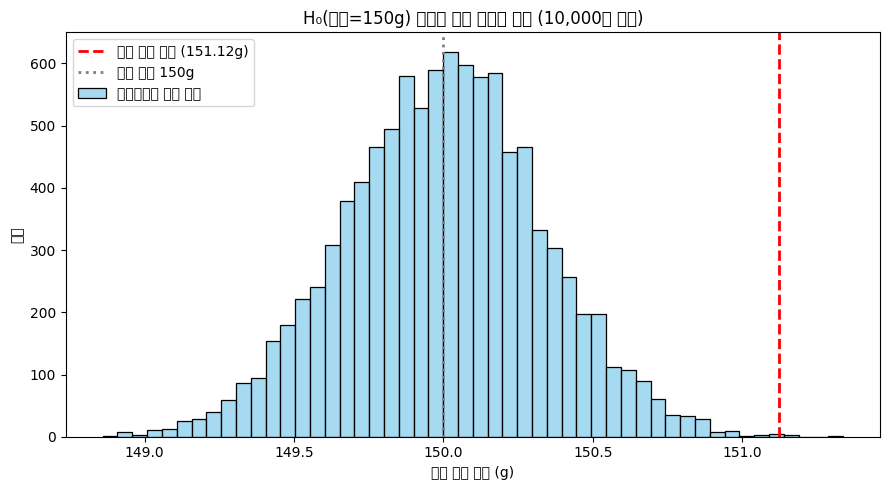

In [15]:
# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))
sns.histplot(sim_means, bins=50, color='skyblue', label='시뮬레이션 표본 평균')
plt.axvline(sample_mean, color='red', linestyle='--', linewidth=2,
            label=f'실제 표본 평균 ({sample_mean:.2f}g)')
plt.axvline(pop_mean, color='gray', linestyle=':', linewidth=2, label='목표 중량 150g')
plt.title(f'H₀(평균=150g) 하에서 표본 평균의 분포 ({n_sim:,}회 반복)')
plt.xlabel('표본 평균 무게 (g)')
plt.ylabel('빈도')
plt.legend()
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)

- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)

In [16]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 표본평균의 분포,  중심극한정리에 의해 표본이 커지므로 정규분포와 유사하게 간다 .

2. 흔하지않다.  시뮬레이션 평균들은 149~151g사이에 몰려 있다. 반면 실제 평균 151.12g은 오른쪽 꼬리 끝에 있어 그 너머에 있는 막대가 거의 없다.

3. P-value값이 0.001이면 세로선은 그래프에서 더 오른쪽으로 예상된다.

4. 공장입장에서는 평균보다 1.1g 더 무겁게 나오고 있으니, 충전기계를 점검하고 조정해서 평균 150g에 맞춰야한다. 만약 맞추지 않으면 공장입장에서는 손실이 많이 발생한다.

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

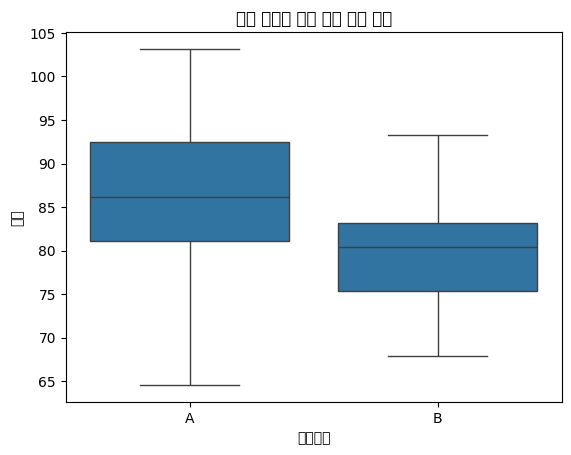

In [17]:
# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

df_scores = pd.DataFrame({'점수': np.concatenate([group_a_scores, group_b_scores]),
                          '학습방식': ['A']*50 + ['B']*50})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x='학습방식', y='점수', data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

In [18]:
# [문제 3] Q1. 두 그룹에 대해 각각 정규성 검정(Shapiro-Wilk test)을 수행하고 p-값을 출력해봅시다.
# H₀: 데이터는 정규분포를 따른다.

# 여기에 코드를 작성해주세요.
alpha = 0.05
shapiro_a = stats.shapiro(group_a_scores)
shapiro_b = stats.shapiro(group_b_scores)
print(f"A그룹 Shapiro-Wilk p-값: {shapiro_a.pvalue:.4f}")
print(f"B그룹 Shapiro-Wilk p-값: {shapiro_b.pvalue:.4f}")

A그룹 Shapiro-Wilk p-값: 0.8766
B그룹 Shapiro-Wilk p-값: 0.8366


In [19]:
# [문제 3] Q2. 두 그룹에 대해 등분산성 검정(Levene's test)을 수행하고 p-값을 출력해봅시다.
# H₀: 두 그룹의 분산은 같다.

# 여기에 코드를 작성해주세요.
levene_result = stats.levene(group_a_scores, group_b_scores)
print(f"\nLevene 검정 p-값: {levene_result.pvalue:.4f}")

equal_var = levene_result.pvalue >= alpha
if equal_var:
    print("→ 등분산성 가정을 만족합니다. (equal_var=True)")
else:
    print("→ 등분산성 가정을 만족하지 않습니다. (equal_var=False, Welch's t-test)")



Levene 검정 p-값: 0.0150
→ 등분산성 가정을 만족하지 않습니다. (equal_var=False, Welch's t-test)


In [20]:
# [문제 3] Q3. 이표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
# 등분산성 가정을 만족했는지 여부에 따라 equal_var 인수를 설정해보세요.

# 여기에 코드를 작성해주세요.
t_stat, p_value = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)
print(f"\nA그룹 평균: {group_a_scores.mean():.2f}, B그룹 평균: {group_b_scores.mean():.2f}")
print(f"t-통계량: {t_stat:.4f}")
print(f"p-값: {p_value:.6f}")

if p_value < alpha:
    print(f"p-값 < {alpha} → 귀무가설 기각: 두 학습 방식의 평균 점수는 다르다고 볼 수 있습니다.")
else:
    print(f"p-값 ≥ {alpha} → 귀무가설 기각 실패: 평균 점수가 다르다는 근거가 부족합니다.")



A그룹 평균: 86.12, B그룹 평균: 79.85
t-통계량: 4.0426
p-값: 0.000115
p-값 < 0.05 → 귀무가설 기각: 두 학습 방식의 평균 점수는 다르다고 볼 수 있습니다.


In [21]:
# [문제 3] Q4. H₀가 사실(두 그룹의 평균이 같다)이라고 가정하고 시뮬레이션을 10,000번 수행해봅시다.
# 두 그룹의 데이터를 모두 합친 뒤(np.concatenate), 매 반복마다 비복원추출로 50개(가상 A그룹)와
# 나머지 50개(가상 B그룹)로 나누어 두 그룹의 평균 차이를 계산하고 리스트에 저장해보세요.
# 힌트: np.random.permutation 을 사용해보세요.

# 여기에 코드를 작성해주세요.
np.random.seed(42)
all_scores = np.concatenate([group_a_scores, group_b_scores])
observed_diff = group_a_scores.mean() - group_b_scores.mean()
n_sim = 10_000

sim_diffs = []
for _ in range(n_sim):
    shuffled = np.random.permutation(all_scores)   # 전체 점수를 무작위로 섞기
    fake_a = shuffled[:50]                         # 앞 50개 → 가상 A그룹
    fake_b = shuffled[50:]                         # 뒤 50개 → 가상 B그룹
    sim_diffs.append(fake_a.mean() - fake_b.mean())

sim_diffs = np.array(sim_diffs)

# 양측검정: 관찰된 차이만큼 이상(양쪽 방향) 벌어진 비율
sim_p_value = np.mean(np.abs(sim_diffs) >= abs(observed_diff))
print(f"\n관찰된 평균 차이(A - B): {observed_diff:.2f}점")
print(f"시뮬레이션 기반 p-값: {sim_p_value:.4f}")


관찰된 평균 차이(A - B): 6.27점
시뮬레이션 기반 p-값: 0.0001


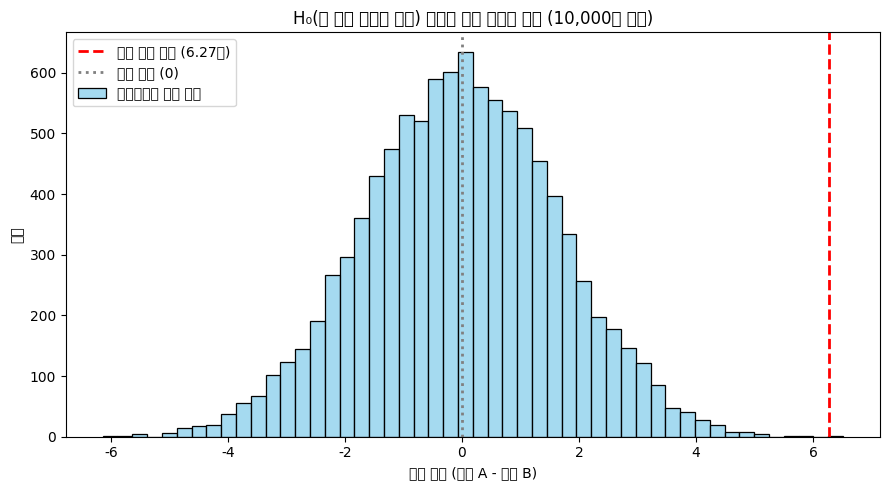

In [22]:
# [문제 3] Q5. 시뮬레이션으로 얻은 평균 차이의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 평균 차이(A그룹 평균 - B그룹 평균)를 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))
sns.histplot(sim_diffs, bins=50, color='skyblue', label='시뮬레이션 평균 차이')
plt.axvline(observed_diff, color='red', linestyle='--', linewidth=2,
            label=f'실제 평균 차이 ({observed_diff:.2f}점)')
plt.axvline(0, color='gray', linestyle=':', linewidth=2, label='차이 없음 (0)')
plt.title(f'H₀(두 그룹 평균이 같음) 하에서 평균 차이의 분포 ({n_sim:,}회 반복)')
plt.xlabel('평균 차이 (가상 A - 가상 B)')
plt.ylabel('빈도')
plt.legend()
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?

- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

In [23]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 두 검정 모두 귀무가설이 ‘정규분포를 따른다’ 이기 때문에 A그룹, B그룹 p-value값이  알파 값 보다  크므로  귀무가설을 기각할 수 없고, 정규성 가정에 문제가 없다

2. A반,B반을 무작위로 섞었기 떄문이다. 섞고 나면 가상 A반과 B반은 같은 점수 묶음에서 아무렇게나 나눈 것이라, 어느쪽이 더 
높아야할 이유가 없다. 

3. 벗어나있다. 이름표를 섞었을 때 생기는 평균 차이는 대부분 약 -3~3점 사이에 몰려있다. 반면 6.27점은 분포의 오른쪽 꼬리를 훨씬 넘어선 위치에 있다. 10,000번 섞는동안 이만큼 벌어진 경우가 거의 없으니, 우연이라고 보기 어렵다.

4. 같은 표현이다. 하나는 그림으로 표현했고, 하나는 수식으로 표현했다.

5. 예를 들어 A반은 학원을 다니는 반이고 B반은 학원을 다니지 않은 반이였다면  학원을 다녀야 성적이 오른다고 광고를 할 수 있다.

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
      액션  로맨스
20대    70      30
30대    50      60
40대    30      60


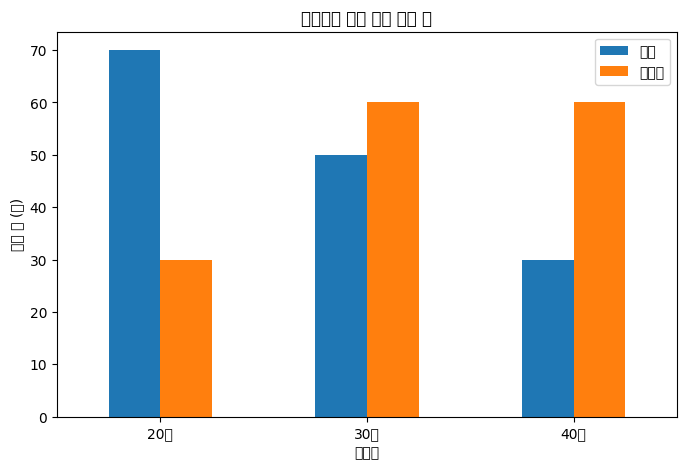

In [24]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [25]:
# [문제 4] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설):연령대와 선호장르 서로 독립이다
# H₁ (대립가설):연령대와 선호장르가 서로 독립이 아니다

In [26]:
# [문제 4] Q2. 카이제곱 독립성 검정을 수행하고 카이제곱 통계량, p-값, 자유도, 기대 빈도를 구해봅시다.
# 기대 빈도는 관측 빈도와 비교하기 쉽도록 데이터프레임 형태로 출력해보세요.

# 여기에 코드를 작성해주세요.
chi2_stat, p_value, dof, expected = stats.chi2_contingency(observed)

expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

print(f"\n카이제곱 통계량: {chi2_stat:.4f}")
print(f"p-값: {p_value:.8f}")
print(f"자유도: {dof}")
print("\n기대 빈도 (Expected Frequencies):")
print(expected_df)

alpha = 0.05
if p_value < alpha:
    print(f"\np-값 < {alpha} → 귀무가설 기각: 연령대에 따라 선호 장르에 차이가 있다고 볼 수 있습니다.")
else:
    print(f"\np-값 ≥ {alpha} → 귀무가설 기각 실패: 연령대와 선호 장르가 관련 있다는 근거가 부족합니다.")



카이제곱 통계량: 26.9091
p-값: 0.00000143
자유도: 2

기대 빈도 (Expected Frequencies):
      액션  로맨스
20대  50.0    50.0
30대  55.0    55.0
40대  45.0    45.0

p-값 < 0.05 → 귀무가설 기각: 연령대에 따라 선호 장르에 차이가 있다고 볼 수 있습니다.


In [27]:
# [문제 4] Q3. H₀가 사실(두 변수가 독립)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 각 반복마다 300명의 가상 고객에게 연령대와 장르를 '독립적으로' 할당한 후,
# 가상 분할표를 만들고 카이제곱 통계량을 계산하여 리스트에 저장해보세요.
# 힌트 1: 전체 비율(observed.sum(axis=0) / 전체, observed.sum(axis=1) / 전체)을 확률로 사용
# 힌트 2: np.random.choice 로 300명의 연령대와 장르를 각각 독립적으로 생성
# 힌트 3: pd.crosstab 으로 분할표 생성 후 stats.chi2_contingency 로 통계량 계산

# 여기에 코드를 작성해주세요.
total = observed.values.sum()                       # 전체 고객 수 (300명)
age_probs = observed.sum(axis=1) / total            # 연령대 비율
genre_probs = observed.sum(axis=0) / total          # 장르 비율

n_sim = 5_000
sim_chi2 = []

for _ in range(n_sim):
    # 연령대와 장르를 서로 '독립적으로' 무작위 할당
    fake_ages = np.random.choice(age_probs.index, size=total, p=age_probs.values)
    fake_genres = np.random.choice(genre_probs.index, size=total, p=genre_probs.values)

    # 가상 분할표 생성 후 카이제곱 통계량 계산
    fake_table = pd.crosstab(fake_ages, fake_genres)
    stat, _, _, _ = stats.chi2_contingency(fake_table)
    sim_chi2.append(stat)

sim_chi2 = np.array(sim_chi2)

# 관찰된 통계량 이상으로 큰 값이 나온 비율 (카이제곱 검정은 오른쪽 꼬리만 봄)
sim_p_value = np.mean(sim_chi2 >= chi2_stat)
print(f"\n시뮬레이션 카이제곱 통계량 평균: {sim_chi2.mean():.2f}")
print(f"시뮬레이션 기반 p-값: {sim_p_value:.4f}")



시뮬레이션 카이제곱 통계량 평균: 1.99
시뮬레이션 기반 p-값: 0.0000


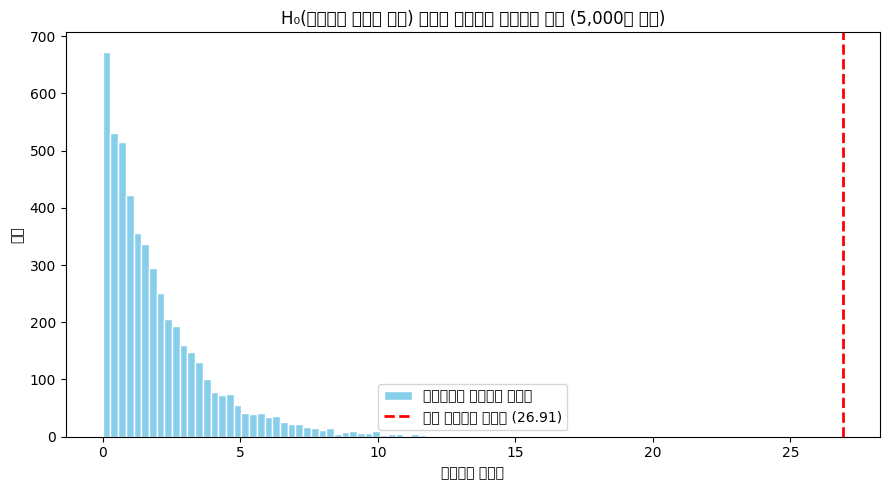

In [28]:
# [문제 4] Q4. 시뮬레이션으로 얻은 카이제곱 통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 카이제곱 통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))
plt.hist(sim_chi2, bins=50, color='skyblue', edgecolor='white', label='시뮬레이션 카이제곱 통계량')
plt.axvline(chi2_stat, color='red', linestyle='--', linewidth=2,
            label=f'실제 카이제곱 통계량 ({chi2_stat:.2f})')
plt.title(f'H₀(연령대와 장르가 독립) 하에서 카이제곱 통계량의 분포 ({n_sim:,}회 반복)')
plt.xlabel('카이제곱 통계량')
plt.ylabel('빈도')
plt.legend()
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?

- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?

- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?

In [29]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 기대 빈도는 이론상 기대되는 값이고, 관측빈도는 실제 관측된 값이다. 관측빈도와 기대빈도에 차이가 작으면 내 데이터는 이론에 잘 맞는거고 차이가 크면  내 데이터는 이론에 따르지 않느다.

2. 히스토그램은 카이제곱통계량 분포를 시각화했다. 극단적인값 이다.

3. alpha값이 p-value보다 크므로 귀무가설은 기각된다. 즉 연령대와 선호장르 사이에 통계적으로 유의미한 연관성이 있다고 본다.

4. 연량대에 따라 선호하는 장르가 다르므로 연대래를 나눠서 홍보를 해야한다. 

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

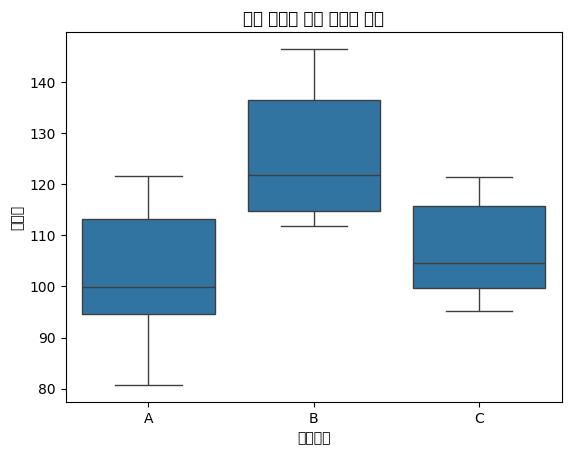

In [30]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

In [31]:
# [문제 5] Q1. 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.

# 여기에 코드를 작성해주세요.
f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

print("그룹별 평균 수확량:")
print(df.groupby('비료종류')['수확량'].mean().round(2))
print(f"\nF-통계량: {f_stat:.4f}")
print(f"p-값: {p_value:.6f}")


그룹별 평균 수확량:
비료종류
A    102.30
B    125.98
C    107.15
Name: 수확량, dtype: float64

F-통계량: 10.3455
p-값: 0.000462


In [32]:
# [문제 5] Q2. ANOVA의 p-값이 유의수준 0.05보다 작을 경우에만
# Tukey's HSD 사후분석을 수행하고 결과를 출력해봅시다.
# 힌트: pairwise_tukeyhsd(endog=수확량, groups=비료종류, alpha=0.05)

# 여기에 코드를 작성해주세요.
alpha = 0.05
if p_value < alpha:
    print(f"\np-값 < {alpha} → 귀무가설 기각: 적어도 하나의 비료 평균 수확량이 다릅니다.")
    print("Tukey's HSD 사후분석을 수행합니다.\n")
    tukey_result = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=alpha)
    print(tukey_result)
else:
    print(f"\np-값 ≥ {alpha} → 귀무가설 기각 실패: 사후분석을 수행하지 않습니다.")



p-값 < 0.05 → 귀무가설 기각: 적어도 하나의 비료 평균 수확량이 다릅니다.
Tukey's HSD 사후분석을 수행합니다.

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------


In [33]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

# 여기에 코드를 작성해주세요.
all_yields = df['수확량'].values
pooled_mean = all_yields.mean()           # 전체 데이터 평균
pooled_std = all_yields.std(ddof=1)       # 전체 데이터 표준편차
n_sim = 5_000

sim_f_stats = []
for _ in range(n_sim):
    # 같은 모집단에서 10개씩 3개의 가상 그룹 생성
    fake_a = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)
    fake_b = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)
    fake_c = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)

    f, _ = stats.f_oneway(fake_a, fake_b, fake_c)
    sim_f_stats.append(f)

sim_f_stats = np.array(sim_f_stats)

# F-통계량도 오른쪽 꼬리만 봄
sim_p_value = np.mean(sim_f_stats >= f_stat)
print(f"\n시뮬레이션 기반 p-값: {sim_p_value:.4f}")



시뮬레이션 기반 p-값: 0.0000


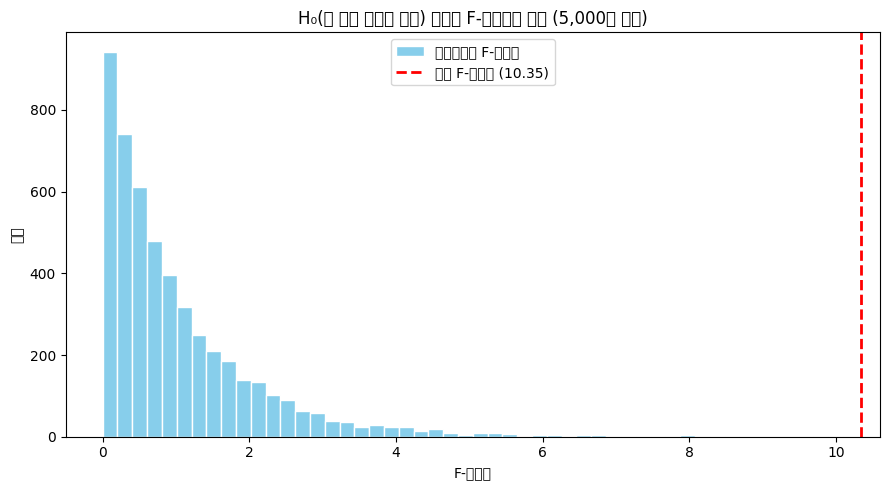

In [34]:
# [문제 5] Q4. 시뮬레이션으로 얻은 F-통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 F-통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(9, 5))
plt.hist(sim_f_stats, bins=50, color='skyblue', edgecolor='white', label='시뮬레이션 F-통계량')
plt.axvline(f_stat, color='red', linestyle='--', linewidth=2,
            label=f'실제 F-통계량 ({f_stat:.2f})')
plt.title(f'H₀(세 비료 평균이 같음) 하에서 F-통계량의 분포 ({n_sim:,}회 반복)')
plt.xlabel('F-통계량')
plt.ylabel('빈도')
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# [문제 5] Q5. 분석 결과를 바탕으로 연구소에 어떤 비료를 추천하시겠습니까?
# 여기에 의견을 작성해주세요.
# 결론: 비료 B를 추천한다.
# - ANOVA 결과 세 비료의 평균 수확량에는 유의미한 차이가 있다. (p < 0.05)
# - Tukey 사후분석 결과 B는 A, C보다 평균 수확량이 유의미하게 높다.
# - A와 C 사이에는 유의미한 차이가 없다.

**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?

- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?

- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?

- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?

In [36]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. alpha값이 p-value보다 크므로 귀무가설은 기각되고 대립가설이 채택된다. 그리므로 적어도 하나는 다르다’ 라는 뜻을 가진다.

2. (A,B), (B,C)조합이 True로 표시되었다. ‘두 비료의 평균이 같다’ 라는 말을 기각한다는 뜻이다.

3. meandiff는 group2 평균이에서 group1 평균 을 뺀 값이다. 부호를 보면 어느쪽이 더 큰지, 크기를 보면 얼마나 차이 나는지 알 수 있다.

4. 표본이 작으면 추정이 불안정하다. 10개 만으로는 평균은 우연히 높거나 낮게 나온값이 크게 크게 흔들릴 수 있다.